In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import joblib
import anndata as ad
from scipy.signal import find_peaks
import h5py
import sys
from pathlib import Path



In [2]:
# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
SAVE_DIR.mkdir(exist_ok=True)

SAVEFILES = True
OVERWRITE = True # Overwrite existing simulation files

sys_type = sys.platform

if sys_type == 'darwin':
    sys_name = 'mac'
    r_path_date = '20240730'
    r_dbpath = 'https://www.dropbox.com/scl/fi/pvx434xg8e391bil5b8wd/reducer_mac_0.1_0.1_4_0.5.sav?rlkey=nuwm98ld3guyukz14a9m6ewu7&dl=1'
if sys_type == 'win32': 
    sys_name = 'win'
    r_path_date = '20240820'
    r_dbpath = 'https://www.dropbox.com/s/a0jo15tvh70wrjv/reducer_win_0.1_0.1_4_0.5.sav?dl=1'
if sys_type == 'linux': 
    sys_name = 'linux'
    r_path_date = '20240606'
    r_dbpath = "https://www.dropbox.com/scl/fi/79lp5174wny1ngiy4w1h7/reducer_20240606_0.1_0.1_4_0.5.sav?rlkey=3p1xkbzkdmwy9ivmn5r64xtlh&dl=1"

r_name = f'reducer_{sys_name}_0.1_0.1_4_0.5.sav'

r_path = Path(SAVE_DIR,'UMAP',r_name)

%env R_PATH = {r_path}
%env R_DBPATH = {r_dbpath}

env: R_PATH=C:\Users\olesk\ECM_mod_output\UMAP\reducer_win_0.1_0.1_4_0.5.sav
env: R_DBPATH=https://www.dropbox.com/s/a0jo15tvh70wrjv/reducer_win_0.1_0.1_4_0.5.sav?dl=1


In [3]:
prot = joblib.load(Path(SAVE_DIR, f'all_prot_stoch_conds_{sys_name}_orig.sav'))
umap_embed = joblib.load(Path(SAVE_DIR, f'all_embedding_stoch_conds_{sys_name}_orig.sav')) # corresponding UMAP embedded data
prot_d = joblib.load(SAVE_DIR / f'all_prot_stoch_cdk46i_{sys_name}.sav')  # windowed data
umap_d_embed = joblib.load(SAVE_DIR / f'all_embedding_stoch_cdk46i_{sys_name}.sav') # corresponding UMAP embedded data


### Load data from 07_cellxgene_prep

In [4]:
adata = ad.read_h5ad(Path(SAVE_DIR,'orig_params_1022-wELong.h5ad'))

In [5]:
adata.obs.columns

Index(['drug', 'stiffness', 'G1_time'], dtype='object')

In [6]:
def getIMT(prot):
    peaks_E, _ = find_peaks(prot[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(prot[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    time_st = 0.1

    #Padding for beginning of run
    tmp = np.empty((peaks_E[3],1))
    tmp[:] = np.nan
    tmp_ind = tmp
    div_time = pd.DataFrame(tmp)

    div_inds = pd.DataFrame(tmp)
    div_phase = pd.DataFrame(tmp)
    ii=0
    
    for n in range(3,len(peaks_E)-3):   #make sure we have divisions at ends 
        tmp_g1_s = peaks_E[n]
        tmp_g1_s_2 = peaks_E[n+1]
        tmp_g1_s_3 = peaks_E[n+2]  
        
        tmp_mit = peaks_cdc[(tmp_g1_s < peaks_cdc) & (peaks_cdc < tmp_g1_s_2)]
        tmp_mit2 = peaks_cdc[(tmp_g1_s_2 < peaks_cdc) & (peaks_cdc < tmp_g1_s_3)]
          
             
        if (np.size(tmp_mit) > 0) & (np.size(tmp_mit2)>0):
            ordered = [tmp_g1_s, tmp_mit[0], tmp_g1_s_2, tmp_mit2[0], tmp_g1_s_3]
            g1_len_tmp = np.array([ordered[2]*time_st]) - np.array([ordered[1]*time_st])
            tmp = [g1_len_tmp]*int(ordered[2]-ordered[0])
            tmp_ind = [np.array([ii])]*int(ordered[2]-ordered[0])
            tmp_g1 = ['G1']*int(ordered[2]-ordered[1])
            tmp_s_m = ['S-G2-M']*int(ordered[1]-ordered[0])
            tmp = np.concatenate(tmp, axis=0)
            tmp_ind = np.concatenate(tmp_ind, axis=0)

            tmp_df = pd.DataFrame(tmp)
            tmp_df_ind = pd.DataFrame(tmp_ind)
            tmp_g1_df = pd.DataFrame(tmp_g1)
            tmp_s_m_df = pd.DataFrame(tmp_s_m)            

            div_time = pd.concat([div_time, tmp_df], ignore_index=True)
            div_inds = pd.concat([div_inds, tmp_df_ind], ignore_index=True)
            div_phase = pd.concat([div_phase, tmp_s_m_df], ignore_index=True)
            div_phase = pd.concat([div_phase, tmp_g1_df], ignore_index=True)
            
            ii+=1
        else:
            tmp = np.empty((int(peaks_E[n+1]-peaks_E[n]),1))
            tmp[:] = np.nan
            tmp_df = pd.DataFrame(tmp)
            div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
            div_inds = pd.concat([div_inds, tmp_df], ignore_index=True)
            div_phase = pd.concat([div_phase, tmp_df], ignore_index=True)

            ii+=1

    # Padding for end of run
    tmp = np.empty((len(prot)-peaks_E[-3],1))
    tmp[:] = np.nan
    tmp_df = pd.DataFrame(tmp)
    div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
    div_inds = pd.concat([div_inds, tmp_df], ignore_index=True)
    div_phase = pd.concat([div_phase, tmp_df], ignore_index=True)
    
    return div_time, div_inds, div_phase

In [7]:
# tmp_g1 = ['G1']*int(5)
# tmp_g1_df = pd.DataFrame(tmp_g1)
# tmp_g1_df

In [8]:
len_prot = int(prot.shape[0]/10)
win_len = int(prot.shape[1]/18)

In [9]:
all_divs = []
all_div_inds = []
all_phase = []
for num in range(10):
    tmp_div, div_inds, div_phase = getIMT(prot[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    tmp_ind_list = div_inds[0].values.tolist()
    tmp_phase = div_phase[0].values.tolist()
    all_divs = all_divs + tmp_list
    all_div_inds = all_div_inds + tmp_ind_list
    all_phase = all_phase + tmp_phase
    print(num)

0
1
2
3
4
5
6
7
8
9


In [10]:
prot_names = ["skp2", "CKI", "pCKI", "cdh1", "myc", "cycD", "cycD-CKI", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-CKI", "cycA", "cycA-CKI",
        "cycB", "cycB-CKI", "cdc20"]

In [11]:
alldata = adata.obs
alldata['G1_val'] = all_divs
alldata['Phase'] = all_phase
alldata['cell_ind'] = all_div_inds
alldata['UMAP1'] = adata.obsm["X_umap"][:,0]
alldata['UMAP2'] = adata.obsm["X_umap"][:,1]
# alldata['G1_time'] = adata.obs["G1_time"]
n=1
for name in prot_names:
    alldata[f"{name}"] = adata.X[:,n]
    n+=3

In [15]:
# test = alldata.loc[(alldata['drug'] == 'ERL') & (alldata['stiffness'] == 0)]


In [16]:
# tmp = test.loc[(test['G1_time'] == 'Long')]

In [19]:
# tmp

In [20]:
# plt.scatter(tmp.UMAP1, tmp.UMAP2, c=tmp.Rb, s=1, alpha=0.2)

In [14]:
lowstiff_erl = alldata.loc[(alldata['drug'] == 'ERL') & (alldata['stiffness'] == 0)]


In [21]:
# test

In [15]:
tmp_ls = lowstiff_erl.loc[(lowstiff_erl['G1_time'] == 'Short') | (lowstiff_erl['G1_time'] == 'Long')]

In [16]:
tmp_s = tmp_ls.loc[(tmp_ls['G1_time'] == 'Short')]
tmp_s_G1 = tmp_s.loc[(tmp_s['Phase'] == 'G1')]
tmp_s_SM = tmp_s.loc[(tmp_s['Phase'] == 'S-G2-M')]
tmp_l = tmp_ls.loc[(tmp_ls['G1_time'] == 'Long')]
tmp_l_G1 = tmp_l.loc[(tmp_l['Phase'] == 'G1')]
tmp_l_SM = tmp_l.loc[(tmp_l['Phase'] == 'S-G2-M')]

In [21]:
def plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool, fig_title=True):
    xmin, xmax = -10, 20
    ymin, ymax = -2, 20
    
    if short_bool:        
        x = np.array(tmp_s.UMAP1)
        y = np.array(tmp_s.UMAP2)
        H_s, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
        x_centers = xedges[:-1] + np.diff(xedges)/2
        y_centers = yedges[:-1] + np.diff(yedges)/2
        
        ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='lightgray', s=0.5, alpha=0.2)
        plt_hndl = ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c=tmp_s[prot], s=0.5, alpha=0.2, vmin=0, vmax=1)

    else:
        x = np.array(tmp_l.UMAP1)
        y = np.array(tmp_l.UMAP2)
        H_l, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
        x_centers = xedges[:-1] + np.diff(xedges)/2
        y_centers = yedges[:-1] + np.diff(yedges)/2
        
        ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='lightgray', s=0.5, alpha=0.2)
        plt_hndl = ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c=tmp_l[prot], s=0.5, alpha=0.2, vmin=0, vmax=1)
        
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax.xaxis.set_ticks(np.arange(-10, 21, step=10))
    ax.yaxis.set_ticks(np.arange(0, 21, step=5))
    ax.tick_params(colors='white', which='both') 
    if fig_title:
        ax.set_title(prot, y=1.0, pad=-14, size=12)
    # plt.xticks(color='w')
    # plt.yticks(color='w')

    return plt_hndl
    

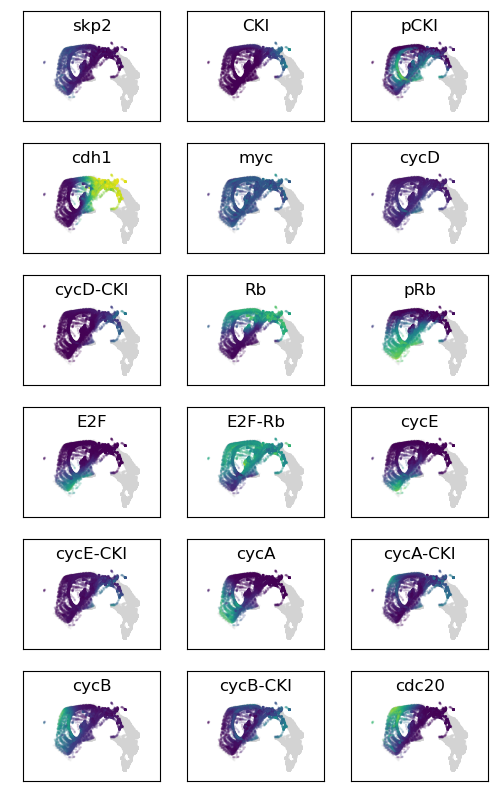

In [22]:
size = (6,10)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 2,
         'ytick.labelsize': 2}
plt.rcParams.update(params)
nrows = 6
ncols = 3

fig = plt.figure(figsize=size)

n=1
for prot in prot_names:
    ax = fig.add_subplot(nrows, ncols, n)
    plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool=True)
    n+=1

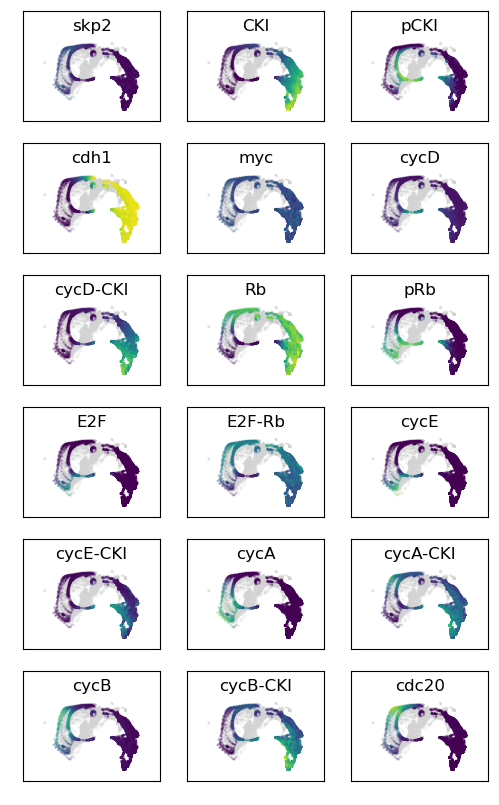

In [23]:
size = (6,10)
plt.rcParams.update(params)
nrows = 6
ncols = 3

fig = plt.figure(figsize=size)

n=1
for prot in prot_names:
    ax = fig.add_subplot(nrows, ncols, n)
    plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool=False)
    n+=1

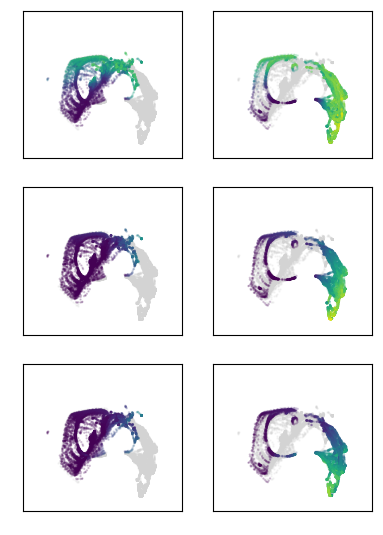

In [24]:
size = (4.5,6.5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 2,
         'ytick.labelsize': 2}
plt.rcParams.update(params)
nrows = 3
ncols = 2

fig, axes = plt.subplots(nrows, ncols, figsize=size, constrained_layout=False)

prots = ['Rb', 'CKI', 'cycD-CKI']

for r in range(nrows):
    prot = prots[r]
    for c in range(ncols):
        if c % 2 == 0:
            im = plot_act(axes[r][c], fig, prot, tmp_s, tmp_l, short_bool=True, fig_title=False)
        else:
            im = plot_act(axes[r][c], fig, prot, tmp_s, tmp_l, short_bool=False, fig_title=False)

# colorbar = fig.colorbar(im, ax=axes, shrink = 0.6)
# colorbar.ax.tick_params(labelsize=12)
# colorbar.set_ticks([0, 0.5, 1])

filepath = Path(SAVE_DIR, 'fig6B_relative_activity.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)

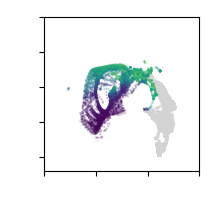

In [26]:
size = (2,2)
prot_to_plot = 'Rb'
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig, ax = plt.subplots(1,1, figsize=size)
xmin, xmax = -10, 20
ymin, ymax = -2, 20

x = np.array(tmp_s.UMAP1)
y = np.array(tmp_s.UMAP2)
H_s, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
x_centers = xedges[:-1] + np.diff(xedges)/2
y_centers = yedges[:-1] + np.diff(yedges)/2

ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='lightgray', s=0.5, alpha=0.2)
ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c=tmp_s[prot_to_plot], s=0.5, alpha=0.2, vmin=0, vmax=1)

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))
plt.xticks(color='w')
plt.yticks(color='w')

filepath = Path(SAVE_DIR, f'fig6B_{prot_to_plot}_short.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)


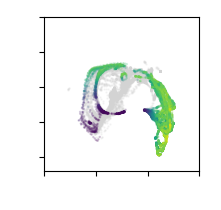

In [27]:
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = -2, 20

x = np.array(tmp_l.UMAP1)
y = np.array(tmp_l.UMAP2)
H_l, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
x_centers = xedges[:-1] + np.diff(xedges)/2
y_centers = yedges[:-1] + np.diff(yedges)/2

plt.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='lightgray', s=0.5, alpha=0.2)
plt.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c=tmp_l[prot_to_plot], s=0.5, alpha=0.2, vmin=0, vmax=1)

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))
plt.xticks(color='w')
plt.yticks(color='w')

filepath = Path(SAVE_DIR, f'fig6B_{prot_to_plot}_long.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)
    

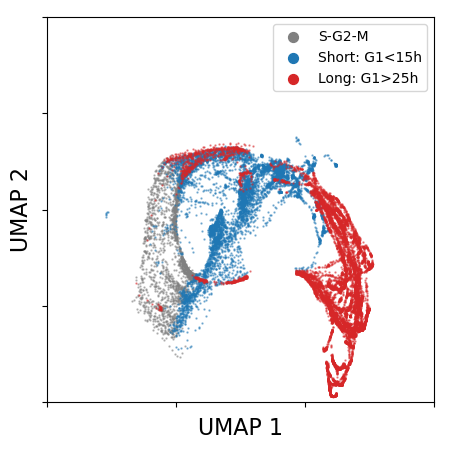

In [29]:
val = 0.0001
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20


plt.scatter(tmp_l_SM.UMAP1, tmp_l_SM.UMAP2, c='gray', s=0.5, alpha=0.5)
plt.scatter(tmp_s_SM.UMAP1, tmp_s_SM.UMAP2, c='gray', s=0.5, alpha=0.5, label="S-G2-M")
plt.scatter(tmp_s_G1.UMAP1, tmp_s_G1.UMAP2, c='tab:blue', s=0.5, alpha=0.5, label="Short: G1<15h")
plt.scatter(tmp_l_G1.UMAP1, tmp_l_G1.UMAP2, c='tab:red', s=0.5, alpha=0.5, label="Long: G1>25h")

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

plt.xlabel('UMAP 1', labelpad=-10)
plt.ylabel('UMAP 2', labelpad=-15)

leg = plt.legend(markerscale=10)
for lh in leg.legend_handles: 
    lh.set_alpha(1)
    
filepath = Path(SAVE_DIR,'fig6A_uniqueG1.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)
